In [1]:
from datasets import load_dataset
import pandas as pd

/home/pasali/anaconda3/envs/myenv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
configs = [
    "sentences_50agree",
    "sentences_66agree",
    "sentences_75agree",
    "sentences_allagree"
]

datasets_dict = {}

for config in configs:
    datasets_dict[config] = load_dataset(
        "takala/financial_phrasebank",
        config,
        revision="refs/pr/10"
    )

Generating train split: 100%|██████████| 2264/2264 [00:00<00:00, 383425.03 examples/s]


In [3]:
for config, dataset in datasets_dict.items():
    print(config, dataset["train"].shape)

sentences_50agree (4846, 2)
sentences_66agree (4217, 2)
sentences_75agree (3453, 2)
sentences_allagree (2264, 2)


In [5]:
for config, dataset in datasets_dict.items():
    print(config)
    display(dataset["train"].to_pandas().head())

sentences_50agree


,sentence,label
0,"According to Gran , the company has no plans t...",1
1,Technopolis plans to develop in stages an area...,1
2,The international electronic industry company ...,0
3,With the new production plant the company woul...,2
4,According to the company 's updated strategy f...,2


sentences_66agree


,sentence,label
0,"According to Gran , the company has no plans t...",1
1,Technopolis plans to develop in stages an area...,1
2,With the new production plant the company woul...,2
3,According to the company 's updated strategy f...,2
4,"For the last quarter of 2010 , Componenta 's n...",2


sentences_75agree


,sentence,label
0,"According to Gran , the company has no plans t...",1
1,With the new production plant the company woul...,2
2,"For the last quarter of 2010 , Componenta 's n...",2
3,"In the third quarter of 2010 , net sales incre...",2
4,Operating profit rose to EUR 13.1 mn from EUR ...,2


sentences_allagree


,sentence,label
0,"According to Gran , the company has no plans t...",1
1,"For the last quarter of 2010 , Componenta 's n...",2
2,"In the third quarter of 2010 , net sales incre...",2
3,Operating profit rose to EUR 13.1 mn from EUR ...,2
4,"Operating profit totalled EUR 21.1 mn , up fro...",2


In [6]:
for config, dataset in datasets_dict.items():
    print(config)
    print("Features:", dataset["train"].features)
    print("Splits:", list(dataset.keys()))
    print()

sentences_50agree
Features: {'sentence': Value('string'), 'label': ClassLabel(names=['negative', 'neutral', 'positive'])}
Splits: ['train']

sentences_66agree
Features: {'sentence': Value('string'), 'label': ClassLabel(names=['negative', 'neutral', 'positive'])}
Splits: ['train']

sentences_75agree
Features: {'sentence': Value('string'), 'label': ClassLabel(names=['negative', 'neutral', 'positive'])}
Splits: ['train']

sentences_allagree
Features: {'sentence': Value('string'), 'label': ClassLabel(names=['negative', 'neutral', 'positive'])}
Splits: ['train']



In [19]:
results = []

for config, dataset in datasets_dict.items():
    df = dataset["train"].to_pandas()

    print(config)
    print("Total:", len(df))
    counts = df["label"].value_counts().sort_index()
    print(df["label"].value_counts().sort_index())
    results.append({
    "Configuration": config,
    "Total": len(df),
    "Negative": counts[0],
    "Neutral": counts[1],
    "Positive": counts[2]
    })
    print()

sentences_50agree
Total: 4846
label
0     604
1    2879
2    1363
Name: count, dtype: int64

sentences_66agree
Total: 4217
label
0     514
1    2535
2    1168
Name: count, dtype: int64

sentences_75agree
Total: 3453
label
0     420
1    2146
2     887
Name: count, dtype: int64

sentences_allagree
Total: 2264
label
0     303
1    1391
2     570
Name: count, dtype: int64



In [21]:
results = pd.DataFrame(results)
print(results)

        Configuration  Total  Negative  Neutral  Positive
0   sentences_50agree   4846       604     2879      1363
1   sentences_66agree   4217       514     2535      1168
2   sentences_75agree   3453       420     2146       887
3  sentences_allagree   2264       303     1391       570


In [25]:
from pathlib import Path
import matplotlib.pyplot as plt

Path("../reports").mkdir(parents=True, exist_ok=True)

results.to_csv("../reports/agreement_comparison.csv", index=False)

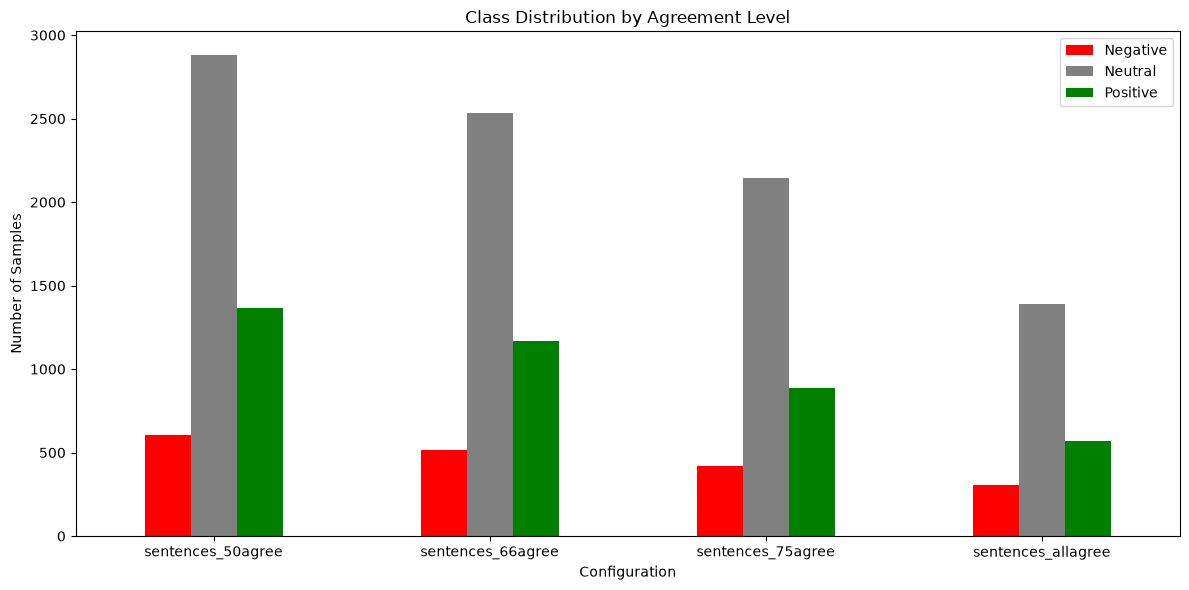

In [26]:
results.set_index("Configuration")[["Negative", "Neutral", "Positive"]].plot(
    kind="bar",
    figsize=(12, 6),
    color=["red", "gray", "green"]
)

plt.title("Class Distribution by Agreement Level")
plt.xlabel("Configuration")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../figures/class_distribution.png", dpi=300)
plt.show()

In [42]:
quality_results = []

for config, dataset in datasets_dict.items():
    df = dataset["train"].to_pandas()

    lengths = df["sentence"].str.split().str.len()
    conflicts = df.groupby("sentence")["label"].nunique()

    quality_results.append({
        "Configuration": config,
        "Total": len(df),
        "Missing Sentences": df["sentence"].isnull().sum(),
        "Missing Labels": df["label"].isnull().sum(),
        "Empty Sentences": df["sentence"].str.strip().eq("").sum(),
        "Duplicate Sentences": df["sentence"].duplicated().sum(),
        "Conflicting Labels": (conflicts > 1).sum(),
        "Min Length": lengths.min(),
        "Mean Length": round(lengths.mean(), 2),
        "Max Length": lengths.max()
    })

quality_df = pd.DataFrame(quality_results)

Path("../reports").mkdir(parents=True, exist_ok=True)

quality_df.to_csv("../reports/data_quality.csv", index=False)

display(quality_df)

,Configuration,Total,Missing Sentences,Missing Labels,Empty Sentences,Duplicate Sentences,Conflicting Labels,Min Length,Mean Length,Max Length
0,sentences_50agree,4846,0,0,0,8,2,2,23.10,81
1,sentences_66agree,4217,0,0,0,6,0,2,23.02,81
2,sentences_75agree,3453,0,0,0,5,0,2,22.76,81
3,sentences_allagree,2264,0,0,0,5,0,2,22.44,81


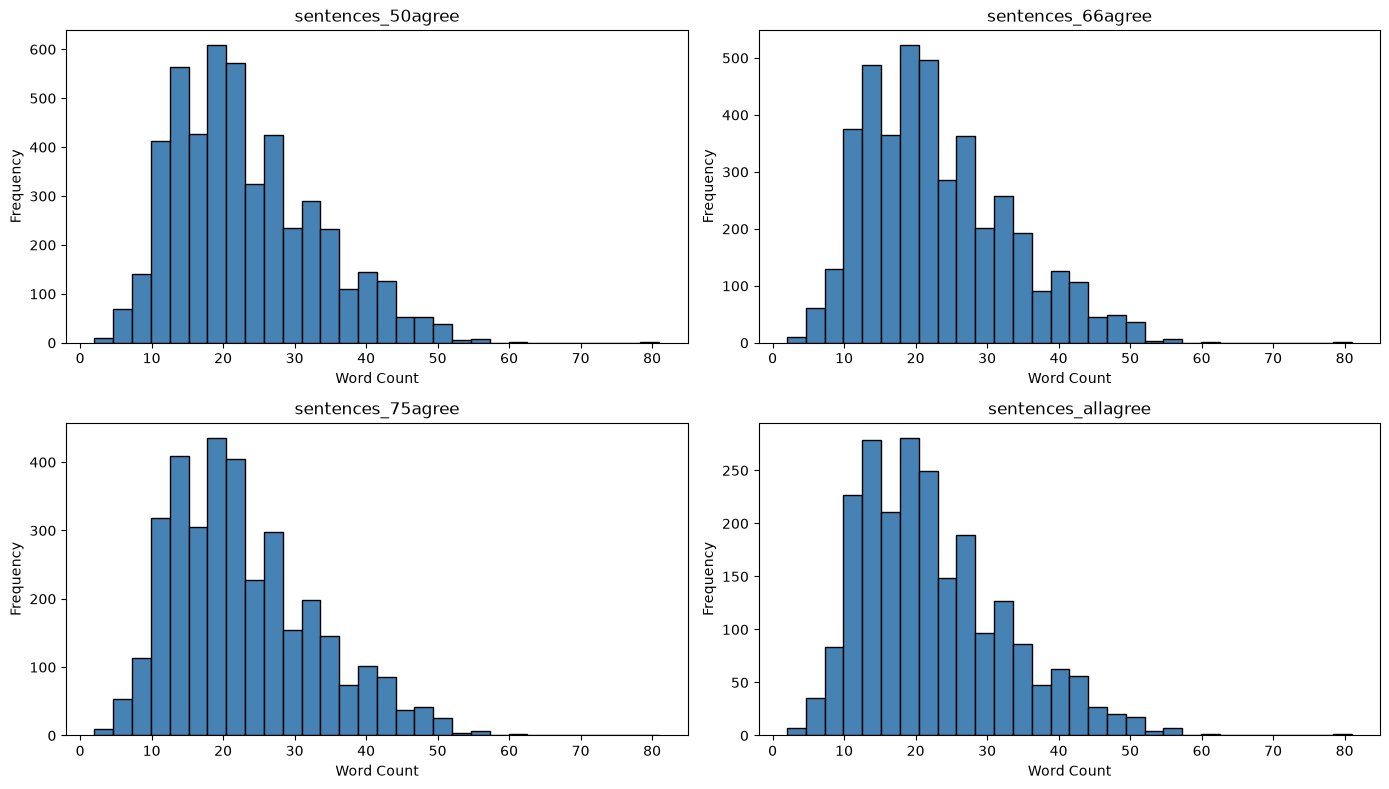

In [43]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for (config, dataset), ax in zip(datasets_dict.items(), axes.flatten()):
    df = dataset["train"].to_pandas()
    lengths = df["sentence"].str.split().str.len()

    ax.hist(lengths, bins=30, color="steelblue", edgecolor="black")
    ax.set_title(config)
    ax.set_xlabel("Word Count")
    ax.set_ylabel("Frequency")

Path("../figures").mkdir(parents=True, exist_ok=True)

plt.tight_layout()
plt.savefig("../figures/sentence_length_distribution.png", dpi=300)
plt.show()

In [44]:
df_50 = datasets_dict["sentences_50agree"]["train"].to_pandas()
df_all = datasets_dict["sentences_allagree"]["train"].to_pandas()

In [47]:
common_sentences = set(df_50["sentence"]).intersection(set(df_all["sentence"]))

print(len(common_sentences))

2259


In [48]:
merged_df = pd.merge(
    df_50.drop_duplicates(),
    df_all.drop_duplicates(),
    on="sentence",
    how="inner",
    suffixes=("_50", "_all")
)

different_labels = merged_df[
    merged_df["label_50"] != merged_df["label_all"]
]

print("Common Sentences:", merged_df["sentence"].nunique())
print("Different Labels:", different_labels["sentence"].nunique())

display(different_labels)

Common Sentences: 2259
Different Labels: 0


,sentence,label_50,label_all


In [51]:
only_50 = df_50[
    ~df_50["sentence"].isin(df_all["sentence"])
]

print(only_50["sentence"].nunique())

2579


In [52]:
sentence_sets = {
    config: set(dataset["train"]["sentence"])
    for config, dataset in datasets_dict.items()
}

intersection_df = pd.DataFrame(
    index=configs,
    columns=configs
)

for config1 in configs:
    for config2 in configs:
        intersection_df.loc[config1, config2] = len(
            sentence_sets[config1].intersection(sentence_sets[config2])
        )

display(intersection_df)

,sentences_50agree,sentences_66agree,sentences_75agree,sentences_allagree
sentences_50agree,4838,4211,3448,2259
sentences_66agree,4211,4211,3448,2259
sentences_75agree,3448,3448,3448,2259
sentences_allagree,2259,2259,2259,2259


In [54]:
groups = {}

for config1, config2 in zip(configs[:-1], configs[1:]):
    groups[config1] = sentence_sets[config1] - sentence_sets[config2]

groups[configs[-1]] = sentence_sets[configs[-1]]

for config, sentences in groups.items():
    df = datasets_dict[config]["train"].to_pandas()

    group_df = df[df["sentence"].isin(sentences)]

    examples = group_df.groupby("sentence")["label"].unique().reset_index()

    print(config)
    display(examples.sample(5, random_state=42))

sentences_50agree


,sentence,label
580,` Pulp and paper industries are growing in cou...,[1]
590,`` Neste Oil has responded to the challenge po...,[2]
550,"Under the contract , Ericsson will more than d...",[1]
213,India is high on our priority since business l...,[1]
485,The personnel reduction will be carried out in...,[0]


sentences_66agree


,sentence,label
357,"Nevertheless , Fitch notes that the business f...",[2]
259,"In Russia , Raisio 's Food Division 's home ma...",[1]
749,`` We are pleased to welcome Tapeks Noma into ...,[2]
193,Finnish financial software developer Basware O...,[2]
333,Merging the two free sheets will clarify the m...,[1]


sentences_75agree


,sentence,label
319,"Following the issue , the number of shares in ...",[1]
1157,`` The CHF is a great product .,[2]
907,The markets are almost completely controlled b...,[1]
86,"Ahlstrom 's 5,800 employees serve customers vi...",[1]
936,The order is a follow-on to an 11 mln euro ( $...,[1]


sentences_allagree


,sentence,label
1573,The company 's net profit amounted to EE 55.5 ...,[2]
368,Dealers said the share was largely hit by inve...,[0]
528,Finnish drug distributor and wholesaler Oriola...,[1]
1530,"The bond , with a maturity of five years , is ...",[1]
56,"561,470 new shares under 2003 option rights pl...",[1]


In [ ]:
selected_config = "sentences_allagree"

financial_df = datasets_dict[selected_config]["train"].to_pandas()

Path("../data").mkdir(parents=True, exist_ok=True)

financial_df.to_csv("../data/financial_sentiment.csv", index=False)

print(financial_df.shape)

(2264, 2)


In [56]:
clean_df = financial_df.drop_duplicates(subset=["sentence"]).reset_index(drop=True)

assert clean_df["label"].isin([0, 1, 2]).all()
print("Label Mapping Test: PASSED")

assert clean_df["sentence"].notna().all()
assert clean_df["sentence"].str.strip().ne("").all()
print("Valid Text Test: PASSED")

assert clean_df["sentence"].duplicated().sum() == 0
print("Duplicate Test: PASSED")

assert set(clean_df["label"].unique()) == {0, 1, 2}
print("Class Distribution Test: PASSED")

print("\nClean Dataset Shape:", clean_df.shape)

Label Mapping Test: PASSED
Valid Text Test: PASSED
Duplicate Test: PASSED
Class Distribution Test: PASSED

Clean Dataset Shape: (2259, 2)
